# Seasonal and Layer Comparison of DO Decorrelation Scales

This notebook summarizes and overlays the decorrelation scales of dissolved oxygen across 4 seasons and 2 depth layers. 


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import cartopy.crs as ccrs
from pathlib import Path
import sys

# Ensure local scripts are importable
project_root = Path("../").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from scripts.paths import ProjectPaths
from scripts.mapping_config import MappingConfig

In [3]:
# Load the results
results = []
seasons = ['spring', 'summer', 'autumn', 'winter']
layers = ['surface', 'bottom']

for season in seasons:
    for layer in layers:
        subset_name = f"{season}_{layer}"
        file_path = ProjectPaths.SEASONAL_DATA_DIR / subset_name / 'stations_decorrelation_scale.csv'
        if file_path.exists():
            df = pd.read_csv(file_path)
            df['Season'] = season.capitalize()
            df['Layer'] = layer.capitalize()
            results.append(df)

all_results = pd.concat(results, ignore_index=True)
# Filter out 0.0 values where decorrelation scale couldn't be solved (e.g. poor fit or short range)
all_results['Decorrelation_Scale_km'] = all_results['Decorrelation_Scale_km'].replace(0.0, np.nan)

# Display Summary
display(all_results.groupby(['Season', 'Layer'])['Decorrelation_Scale_km'].describe())

count       mean        std       min        25%        50%  \
Season Layer                                                                  
Autumn Bottom   124.0  17.969284  10.200426  0.027524  11.888048  16.272769   
       Surface  123.0  17.281171  10.821094  0.025114   9.817740  16.557647   
Spring Bottom   124.0  16.271198  10.051813  0.021416   9.858654  16.500752   
       Surface  124.0  16.886263   8.408365  0.036905  11.818513  16.620930   
Summer Bottom   124.0  13.746867   8.925162  0.023438   7.730693  13.466873   
       Surface  124.0  13.919388   7.767179  0.021132   9.753318  14.438872   
Winter Bottom   121.0  17.314379  10.245830  0.000991  11.061163  16.554644   
       Surface  120.0  19.195636  10.907369  0.016096  12.495428  18.875441   

                      75%        max  
Season Layer                          
Autumn Bottom   24.189085  44.456183  
       Surface  24.697923  39.943744  
Spring Bottom   24.398666  41.330586  
       Surface  22.997304  38.949622  
Summer Bottom   19.835638  41.577851  
       Surface  19.767760  39.455733  
Winter Bottom   24.288709  45.486345  
       Surface  25.113470  49.041218

## 1. Distribution Comparison
Boxplots highlighting seasonal and depth differences in decorrelation scale ($d_x$).

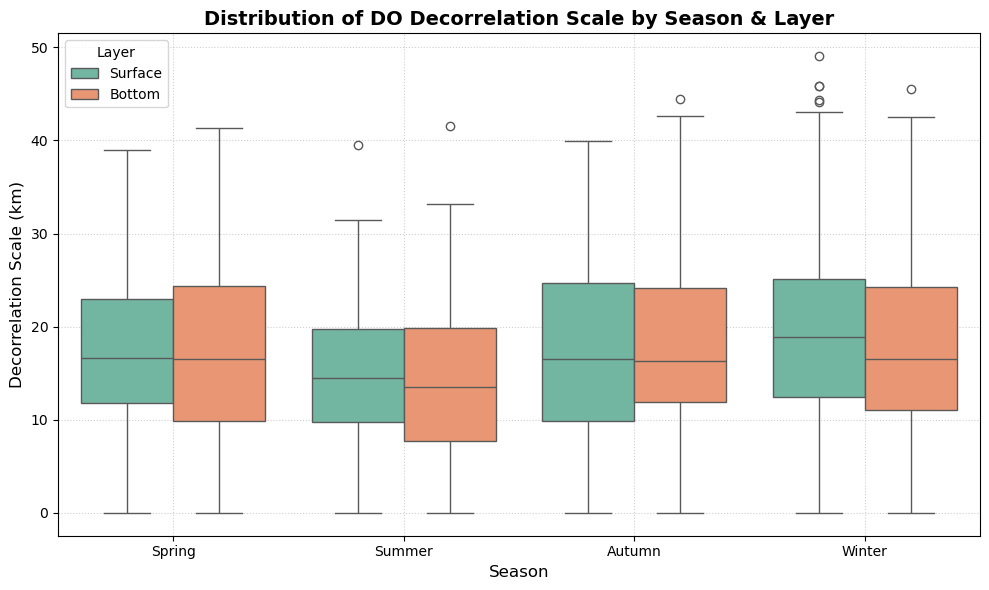

In [4]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=all_results, x='Season', y='Decorrelation_Scale_km', hue='Layer', 
            order=['Spring', 'Summer', 'Autumn', 'Winter'], palette='Set2')
plt.title('Distribution of DO Decorrelation Scale by Season & Layer', fontsize=14, fontweight='bold')
plt.ylabel('Decorrelation Scale (km)', fontsize=12)
plt.xlabel('Season', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## 2. Spatial Distribution Maps
Plotting spatial correlation mappings across 2x4 grid to visualize Seto Inland Sea stations.

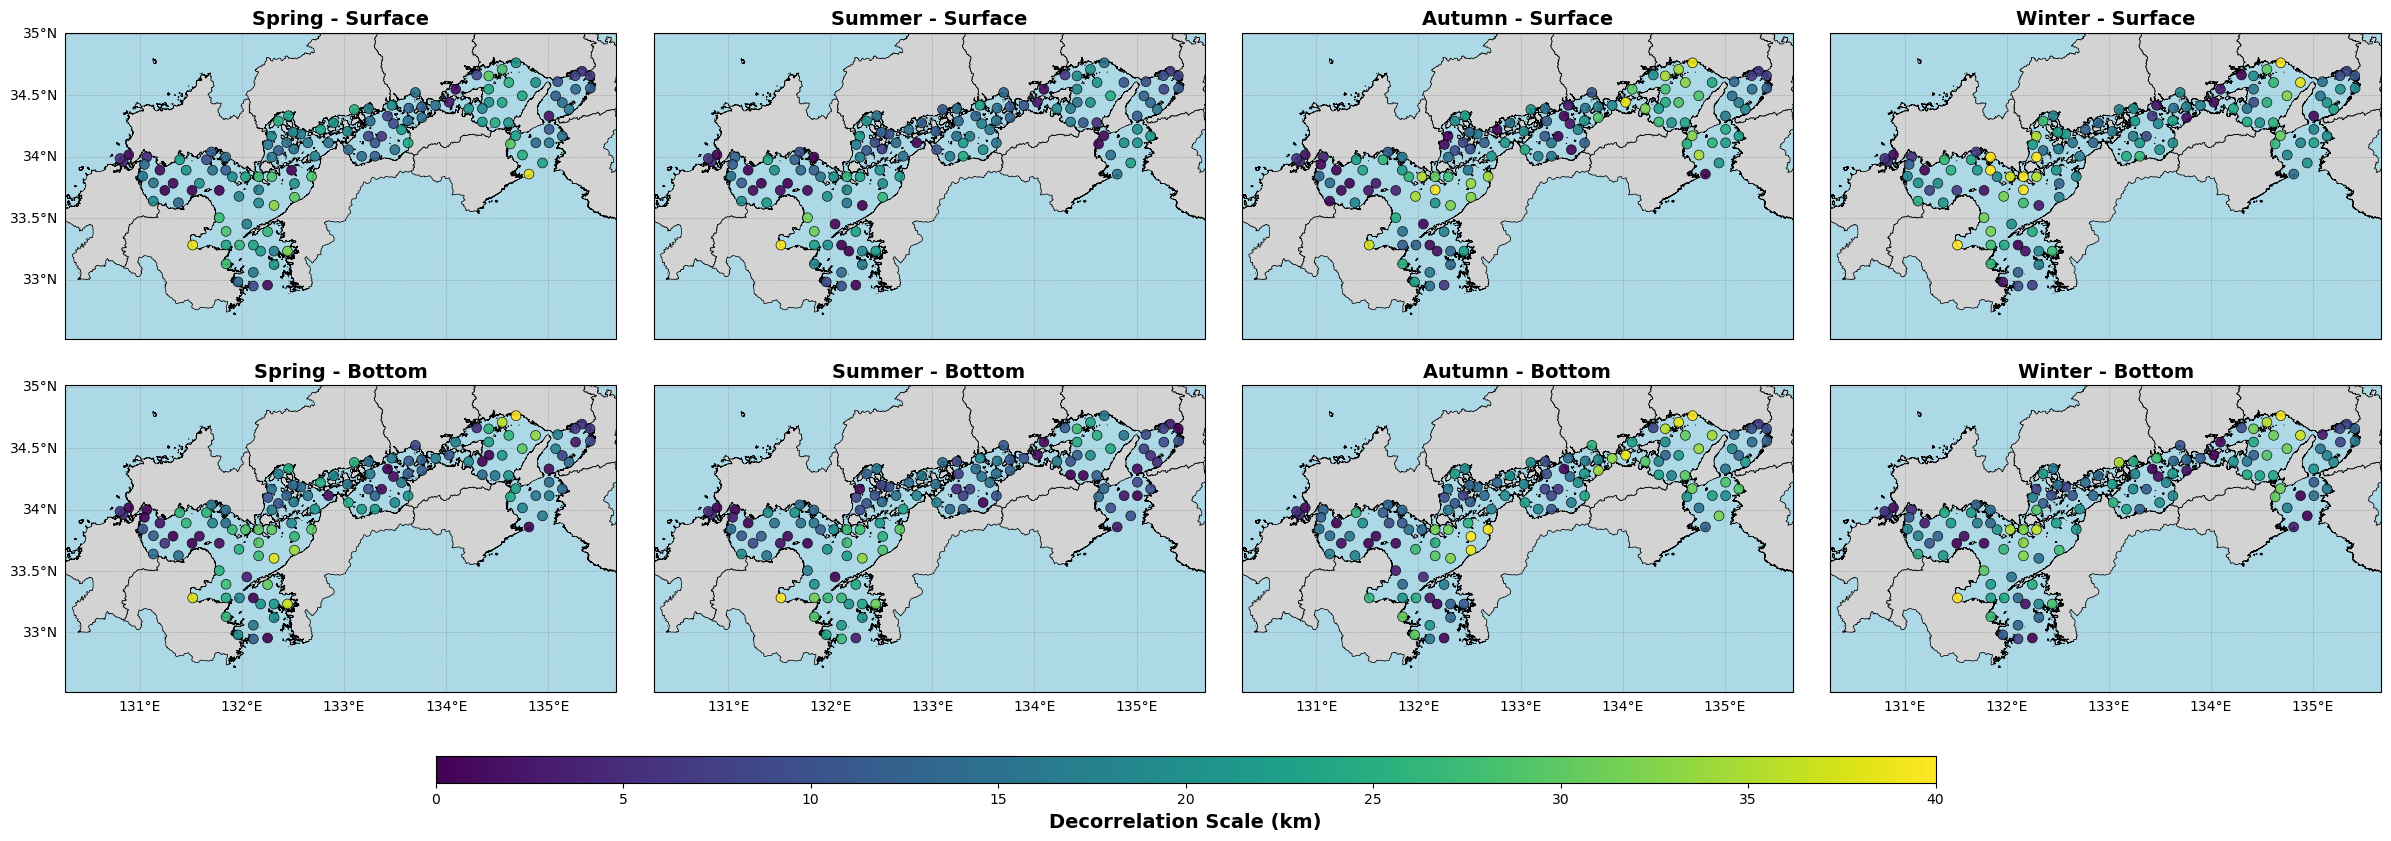

In [10]:
# Merge geometry info into results
merged_gdf = gpd.read_feather(ProjectPaths.MERGED_DATA_FILE)
station_locs = merged_gdf.drop_duplicates('zettaicode').set_index('zettaicode')

all_results['longitude'] = all_results['Station_ID'].astype(str).str.zfill(8).map(lambda x: station_locs.loc[x, 'longitude'] if x in station_locs.index else np.nan)
all_results['latitude'] = all_results['Station_ID'].astype(str).str.zfill(8).map(lambda x: station_locs.loc[x, 'latitude'] if x in station_locs.index else np.nan)

# Drop any unmapped
map_data = all_results.dropna(subset=['latitude', 'longitude', 'Decorrelation_Scale_km']).copy()

# Ensure GeoDataFrame
map_gdf = gpd.GeoDataFrame(map_data, geometry=gpd.points_from_xy(map_data.longitude, map_data.latitude), crs="EPSG:4326")

# Setup 2x4 Map Subplots
water_boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS water mass polygon" / "sea_area_mask_simplified.shp"
sis_water_boundary = gpd.read_file(water_boundary_path)
if sis_water_boundary.crs != "EPSG:4326":
    sis_water_boundary = sis_water_boundary.to_crs("EPSG:4326")
bounds = sis_water_boundary.total_bounds

extent = [bounds[0]-0.2, bounds[2]+0.2, bounds[1]-0.2, bounds[3]+0.2]
aspect_ratio = (extent[3] - extent[2]) / (extent[1] - extent[0])

n_rows = 2
n_cols = 4

fig_width = 30 # Set maximum allowed width
width_per_subplot = fig_width / n_cols
height_per_subplot = (width_per_subplot * aspect_ratio) + 0.3 # 0.3 for title buffer

# Add extra height buffer (e.g. 1.5) for the colorbar at the bottom
fig_height = (height_per_subplot * n_rows) + 1.5 

fig, axes = plt.subplots(n_rows, n_cols, figsize=(fig_width, fig_height), subplot_kw={'projection': ccrs.PlateCarree()})

# Load the land boundary for correct mapping representation
land_boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS_prefecture_boundaries" / "Setonaikai_boundary.shp"
sis_land_boundary = gpd.read_file(land_boundary_path)
if sis_land_boundary.crs != "EPSG:4326":
    sis_land_boundary = sis_land_boundary.to_crs("EPSG:4326")

vmin = 0
vmax = 40

# Iterate
for i, layer in enumerate(layers):
    for j, season in enumerate(seasons):
        ax = axes[i, j]
        ax.set_facecolor(MappingConfig.COLOR_OCEAN)
        
        # Plot land boundary
        sis_land_boundary.plot(ax=ax, facecolor=MappingConfig.COLOR_LAND, edgecolor=MappingConfig.COLOR_LAND_EDGE, 
                               linewidth=MappingConfig.LINEWIDTH_LAND, transform=ccrs.PlateCarree(), 
                               zorder=MappingConfig.ZORDER_LAND)
                               
        gl = ax.gridlines(draw_labels=True, linestyle=MappingConfig.GRID_LINESTYLE, 
                          color=MappingConfig.GRID_COLOR, alpha=MappingConfig.GRID_ALPHA, 
                          linewidth=MappingConfig.GRID_LINEWIDTH, zorder=MappingConfig.ZORDER_GRIDLINES)
        gl.top_labels = False
        gl.right_labels = False
        gl.left_labels = j == 0  # Only show left labels on the first column
        gl.bottom_labels = i == n_rows - 1  # Only show bottom labels on the last row
        
        subset_gdf = map_gdf[(map_gdf['Season'] == season.capitalize()) & (map_gdf['Layer'] == layer.capitalize())]
        
        if not subset_gdf.empty:
            subset_gdf.plot(ax=ax, column='Decorrelation_Scale_km', cmap='viridis',
                            vmin=vmin, vmax=vmax, markersize=50, alpha=0.9,
                            edgecolor='black', linewidth=0.5,
                            transform=ccrs.PlateCarree(), zorder=MappingConfig.ZORDER_PREDICTED)
                             
        ax.set_extent(extent, crs=ccrs.PlateCarree())
        ax.set_title(f"{season.capitalize()} - {layer.capitalize()}", fontsize=14, fontweight='bold')

# CRITICAL: Adjust the grid explicitly instead of tight_layout()
plt.subplots_adjust(bottom=0.15, wspace=0.05, hspace=0.15)

# Colorbar
import matplotlib.cm as cm
import matplotlib.colors as mcolors
sm = cm.ScalarMappable(cmap='viridis', norm=mcolors.Normalize(vmin=vmin, vmax=vmax))
sm.set_array([])

# Add a dedicated colorbar axes [left, bottom, width, height]
# This prevents the colorbar from stealing horizontal width from the plotting axes
cbar_ax = fig.add_axes([0.25, 0.05, 0.5, 0.03]) 
cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
cbar.set_label('Decorrelation Scale (km)', fontsize=14, fontweight='bold')

plt.show()

## 3. Quality vs Scale Check
Investigate the R-squared values to see if differences in scale are correlated to how well the Gaussian decay captures the station's relationships.

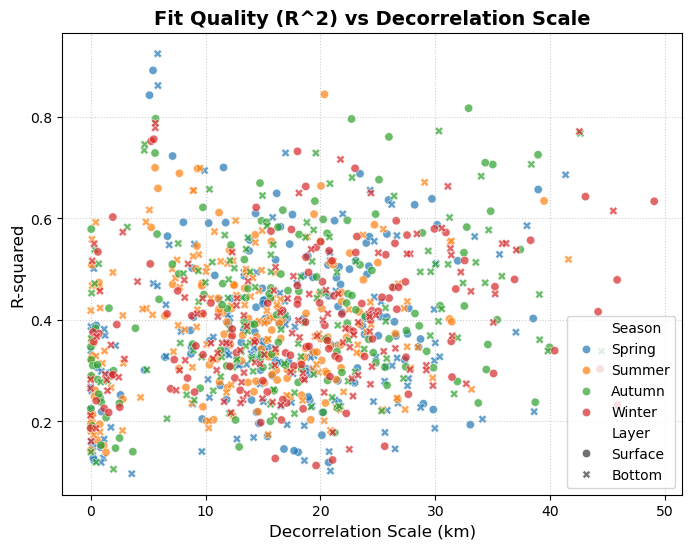

In [5]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=all_results, x='Decorrelation_Scale_km', y='R_squared', hue='Season', style='Layer', alpha=0.7)
plt.title('Fit Quality (R^2) vs Decorrelation Scale', fontsize=14, fontweight='bold')
plt.xlabel('Decorrelation Scale (km)', fontsize=12)
plt.ylabel('R-squared', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()